### الخطوة 1: فحص وتأكيد بيئة التشغيل وتوفر المعالج الرسومي (GPU)
تقوم هذه الخلية بالتحقق من إصدار Python، نظام التشغيل، وإصدار مكتبة PyTorch، بالإضافة إلى التأكد من تفعيل الـ GPU (مثل Tesla T4) ومساحة الذاكرة المتاحة لتسريع عملية تدريب النماذج.

In [1]:
import sys
import torch
import platform

print("=" * 50)
print("ECGFounder Research Environment")
print("=" * 50)

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("WARNING: GPU is not enabled!")

ECGFounder Research Environment
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch version: 2.14.1+cu130

CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU Memory: 14.56 GB


### الخطوة 2: تثبيت والتحقق من المكتبات المطلوبة للعمل
تقوم هذه الخلية بفحص وجود المكتبات الأساسية لمعالجة وتحليل إشارات القلب (مثل `wfdb` و `numpy` و `pandas` و `matplotlib`) وتثبيت أي مكتبة ناقصة تلقائياً لضمان عدم حدوث أخطاء أثناء التشغيل.

In [2]:
# ============================================================
# CELL 2: Install and check required libraries
# ============================================================
import subprocess
import sys
import importlib.util

required_libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "sklearn",
    "scipy",
    "wfdb",
    "tqdm"
]

# Auto-install missing libraries such as 'wfdb'
for library in required_libraries:
    installed = importlib.util.find_spec(library) is not None
    if not installed:
        print(f"Installing missing library: {library}")
        subprocess.run([sys.executable, "-m", "pip", "install", library, "-q"], check=True)

# Verification
for library in required_libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library:15} : {'Installed' if installed else 'Missing'}")

Installing missing library: wfdb
numpy           : Installed
pandas          : Installed
matplotlib      : Installed
seaborn         : Installed
sklearn         : Installed
scipy           : Installed
wfdb            : Installed
tqdm            : Installed


### الخطوة 3: تحميل وفك ضغط مجموعة بيانات تخطيط القلب الشهيرة (PTB-XL)
تقوم هذه الخلية بتحميل ملف البيانات المضغوط لـ PTB-XL مباشرة من موقع PhysioNet، وفك ضغطه في المجلد المخصص، ثم حذف ملف الـ zip لتوفير مساحة القرص التخزيني.

In [3]:
import os
import urllib.request
import zipfile

# تحديد مسار تحميل البيانات وفك الضغط
data_dir = '/content/PTB-XL'
os.makedirs(data_dir, exist_ok=True)

# رابط تحميل مجموعة بيانات PTB-XL الشهيرة لتخطيط القلب
url = 'https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip'
zip_path = os.path.join(data_dir, 'ptb_xl.zip')

print("جاري تحميل بيانات تخطيط القلب (PTB-XL)... قد يستغرق هذا بعض الوقت.")
urllib.request.urlretrieve(url, zip_path)

print("جاري فك ضغط الملفات...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(data_dir)

# حذف ملف الـ zip لتوفير المساحة
os.remove(zip_path)
print("تم تحميل البيانات وفك الضغط عنها بنجاح في:", data_dir)

جاري تحميل بيانات تخطيط القلب (PTB-XL)... قد يستغرق هذا بعض الوقت.
جاري فك ضغط الملفات...
تم تحميل البيانات وفك الضغط عنها بنجاح في: /content/PTB-XL


### الخطوة 4: تأكيد توفر الـ GPU قبل بدء إعداد البيانات
فحص سريع وتأكيدي للتأكد من أن كود التدريب سيعمل على كارت الشاشة (CUDA) لتجنب التدريب البطيء على المعالج التلقائي (CPU).

In [4]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("WARNING: GPU is not enabled.")
    print("Go to Runtime > Change runtime type > T4 GPU")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


### الخطوة 5: التحقق من مسارات وهيكل ملفات البيانات المستخرجة
تقوم هذه الخلية بالبحث عن ملف قاعدة البيانات الرئيسي `ptbxl_database.csv` والتأكد من وجود جميع المجلدات الفرعية التي تحتوي على إشارات تخطيط القلب بتردداتها المختلفة (100Hz و 500Hz).

In [5]:
from pathlib import Path

BASE_DIR = Path("/content/PTB-XL")

database_files = list(
    BASE_DIR.rglob("ptbxl_database.csv")
)

if len(database_files) == 0:
    raise FileNotFoundError(
        "لم يتم العثور على ptbxl_database.csv. تحقق من مكان فك الضغط."
    )

if len(database_files) > 1:
    print("Found multiple database files:")
    for path in database_files:
        print(path)
    raise RuntimeError("حدد مجلد مجموعة البيانات الصحيح.")

DATA_DIR = database_files[0].parent

print("Dataset directory:", DATA_DIR)
print("\nDataset files:")

for name in [
    "ptbxl_database.csv",
    "scp_statements.csv"
]:
    path = DATA_DIR / name
    print(name, "->", path.exists())

print("\nRecords directories:")
for name in ["records500", "records100"]:
    path = DATA_DIR / name
    print(name, "->", path.exists())

Dataset directory: /content/PTB-XL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3

Dataset files:
ptbxl_database.csv -> True
scp_statements.csv -> True

Records directories:
records500 -> True
records100 -> True


### الخطوة 6: قراءة البيانات الوصفية (Metadata) لـ PTB-XL
نقوم هنا بتهيئة وقراءة ملفات الـ CSV الخاصة بالمرضى والتسجيلات وملف `scp_statements.csv` الذي يحتوي على التوصيفات الطبية والتشخيصية لكل تسجيل تخطيط قلب.

In [6]:
import pandas as pd

database_path = DATA_DIR / "ptbxl_database.csv"
statements_path = DATA_DIR / "scp_statements.csv"

df = pd.read_csv(database_path, index_col="ecg_id")
scp = pd.read_csv(statements_path, index_col=0)

print("=" * 55)
print("PTB-XL METADATA REPORT")
print("=" * 55)

print("Database shape:", df.shape)
print("SCP statements shape:", scp.shape)

print("\nDatabase columns:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nSCP statements:")
display(scp.head())

PTB-XL METADATA REPORT
Database shape: (21799, 27)
SCP statements shape: (71, 12)

Database columns:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

First 5 records:


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr



SCP statements:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


### الخطوة 7: استعراض توزيع عينات تخطيط القلب على المجموعات (Folds)
تقوم هذه الخلية بعرض توزيع البيانات على الـ Folds العشرة وحساب حجم البيانات المخصصة للتدريب (من 1 إلى 8)، التحقق (Fold 9)، والاختبار النهائي (Fold 10).

In [7]:
print("Fold distribution:")
display(
    df["strat_fold"]
    .value_counts()
    .sort_index()
    .to_frame("records")
)

train_count = df["strat_fold"].between(1, 8).sum()
val_count = (df["strat_fold"] == 9).sum()
test_count = (df["strat_fold"] == 10).sum()

print("\nDataset split:")
print("Train:", train_count)
print("Validation:", val_count)
print("Test:", test_count)
print("Total:", len(df))

Fold distribution:


,records
strat_fold,
1,2175
2,2181
3,2192
4,2174
5,2174
6,2173
7,2176
8,2173
9,2183



Dataset split:
Train: 17418
Validation: 2183
Test: 2198
Total: 21799


### الخطوة 8: استخلاص وتصنيف الفئات المستهدفة (Target Classes)
تقوم هذه الخلية بتحليل أكواد SCP التشخيصية وتحويلها إلى الفئات الخمس الرئيسية المتفق عليها عالمياً لعلاج أمراض القلب وتصنيفها في شكل مصفوفة ثنائية (Multi-label Classification) وهي:
* **NORM**: طبيعي
* **MI**: احتشاء عضلة القلب
* **STTC**: تغيرات في قطاع ST/T
* **CD**: اضطرابات التوصيل الكهربائي
* **HYP**: تضخم القلب

In [8]:
import ast

TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

# Keep only diagnostic SCP statements
diagnostic_map = (
    scp.loc[scp["diagnostic"] == 1, "diagnostic_class"]
    .dropna()
    .to_dict()
)

def extract_diagnostic_classes(scp_codes):
    if isinstance(scp_codes, str):
        scp_codes = ast.literal_eval(scp_codes)

    classes = set()

    for code in scp_codes:
        diagnostic_class = diagnostic_map.get(code)

        if diagnostic_class in TARGET_CLASSES:
            classes.add(diagnostic_class)

    return classes

# Extract labels
df["diagnostic_classes"] = df["scp_codes"].apply(
    extract_diagnostic_classes
)

# Create multi-label columns
for class_name in TARGET_CLASSES:
    df[class_name] = df["diagnostic_classes"].apply(
        lambda labels: int(class_name in labels)
    )

print("Class distribution:")
display(df[TARGET_CLASSES].sum().to_frame("positive_records"))

print("\nFirst records with labels:")
display(df[TARGET_CLASSES + ["strat_fold"]].head())

print("\nRecords with no target class:",
      (df[TARGET_CLASSES].sum(axis=1) == 0).sum())

Class distribution:


,positive_records
NORM,9514
MI,5469
STTC,5235
CD,4898
HYP,2649



First records with labels:


,NORM,MI,STTC,CD,HYP,strat_fold
ecg_id,,,,,,
1,1,0,0,0,0,3
2,1,0,0,0,0,2
3,1,0,0,0,0,5
4,1,0,0,0,0,3
5,1,0,0,0,0,4



Records with no target class: 411


### الخطوة 9: قراءة إشارة تخطيط قلب فردية للتأكد من سلامة القراءة وعرض خصائصها
تقوم هذه الخلية باستخدام مكتبة `wfdb` لقراءة أول تسجيل تخطيط قلب بالتردد العالي (500Hz) وعرض معلومات الإشارة مثل عدد القنوات (12 Leads) وعدد العينات والقيم العظمى والصغرى للتأكد من عدم وجود قيم مفقودة (NaN).

In [9]:
# ============================================================
# CELL 8: READ SINGLE ECG RECORD WITH WFDB
# Goal: Fix ModuleNotFoundError by auto-installing wfdb
# ============================================================
import subprocess
import sys
import importlib.util

# Ensure wfdb is installed
if importlib.util.find_spec("wfdb") is None:
    print("Installing missing package 'wfdb'...")
    subprocess.run([sys.executable, "-m", "pip", "install", "wfdb", "-q"], check=True)

import wfdb
import numpy as np

# Select first record
record = df.iloc[0]

# Get 500Hz signal path
record_path = DATA_DIR / record["filename_hr"]

print("ECG ID:", df.index[0])
print("Record path:", record_path)

# Read ECG signal
signal, fields = wfdb.rdsamp(str(record_path))

print("\nSignal information:")
print("Sampling frequency:", fields["fs"], "Hz")
print("Signal shape:", signal.shape)
print("Number of leads:", signal.shape[1])
print("Number of samples:", signal.shape[0])
print("Lead names:", fields["sig_name"])

print("\nSignal values:")
print("Minimum:", np.min(signal))
print("Maximum:", np.max(signal))
print("NaN values:", np.isnan(signal).sum())

ECG ID: 1
Record path: /content/PTB-XL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/records500/00000/00001_hr

Signal information:
Sampling frequency: 500 Hz
Signal shape: (5000, 12)
Number of leads: 12
Number of samples: 5000
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

Signal values:
Minimum: -1.444
Maximum: 0.69
NaN values: 0


### الخطوة 10: رسم بياني لإشارة تخطيط القلب لفحص جودتها بصرياً
توليد رسم بياني يعرض الإشارة الكهربية للنبضات عبر القناة الأولى (Lead I) على مدار 10 ثوانٍ للتحقق البصري من جودة الإشارة والتعرف على مستويات التشويش.

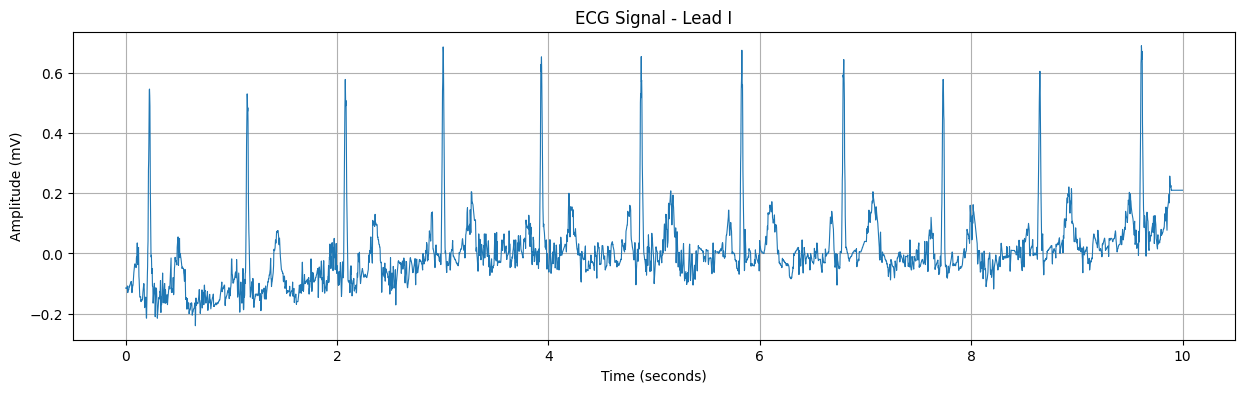

In [10]:
import matplotlib.pyplot as plt

sampling_rate = fields["fs"]
time = np.arange(signal.shape[0]) / sampling_rate

plt.figure(figsize=(15, 4))

plt.plot(time, signal[:, 0], linewidth=0.8)

plt.title(f"ECG Signal - Lead {fields['sig_name'][0]}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

plt.show()

### الخطوة 11: فرز البيانات وبناء خريطة تصنيفات تخطيط القلب النهائية
تقوم هذه الخلية بإنشاء بنية البيانات النهائية اللازمة لبناء نموذج التصنيف، وإظهار التداخل في التصنيفات المتعددة لكل تسجيل وتحديد الحالات التي لا تحمل أي تشخيص.

In [11]:
import pandas as pd
import numpy as np
import ast
from pathlib import Path

# Dataset paths
BASE_DIR = Path("/content/PTB-XL")

database_files = list(BASE_DIR.rglob("ptbxl_database.csv"))
assert len(database_files) == 1, database_files

DATA_DIR = database_files[0].parent

# Load metadata
df = pd.read_csv(DATA_DIR / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(DATA_DIR / "scp_statements.csv", index_col=0)

TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

# Inspect official diagnostic class mapping
print("Diagnostic class distribution in SCP statements:")
print(
    scp["diagnostic_class"]
    .value_counts(dropna=False)
    .to_string()
)

# Create code-to-class mapping
diagnostic_map = (
    scp.loc[scp["diagnostic"].eq(1), "diagnostic_class"]
    .dropna()
    .to_dict()
)

print("\nTarget class mapping:")
for code, class_name in diagnostic_map.items():
    if class_name in TARGET_CLASSES:
        print(f"{code:12} -> {class_name}")

# Extract classes from each ECG record
def extract_classes(value):
    if isinstance(value, str):
        codes = ast.literal_eval(value)
    elif isinstance(value, dict):
        codes = value
    else:
        return set()

    result = set()

    for code in codes:
        class_name = diagnostic_map.get(code)

        if class_name in TARGET_CLASSES:
            result.add(class_name)

    return result

df["diagnostic_classes"] = df["scp_codes"].apply(extract_classes)

# Create multi-label target matrix
for class_name in TARGET_CLASSES:
    df[class_name] = df["diagnostic_classes"].apply(
        lambda x: int(class_name in x)
    )

# Display counts
print("\nPositive records per class:")
for class_name in TARGET_CLASSES:
    print(f"{class_name:8}: {df[class_name].sum():,}")

# Records with no target labels
no_target = df[TARGET_CLASSES].sum(axis=1) == 0

print("\nRecords without target labels:", no_target.sum())
print("Records with at least one target:", (~no_target).sum())

# Multi-label overlap
print("\nNumber of labels per record:")
print(df[TARGET_CLASSES].sum(axis=1).value_counts().sort_index().to_string())

print("\nFirst 10 target records:")
print(df[TARGET_CLASSES].head(10).to_string())

Diagnostic class distribution in SCP statements:
diagnostic_class
NaN     27
MI      14
STTC    13
CD      11
HYP      5
NORM     1

Target class mapping:
NDT          -> STTC
NST_         -> STTC
DIG          -> STTC
LNGQT        -> STTC
NORM         -> NORM
IMI          -> MI
ASMI         -> MI
LVH          -> HYP
LAFB         -> CD
ISC_         -> STTC
IRBBB        -> CD
1AVB         -> CD
IVCD         -> CD
ISCAL        -> STTC
CRBBB        -> CD
CLBBB        -> CD
ILMI         -> MI
LAO/LAE      -> HYP
AMI          -> MI
ALMI         -> MI
ISCIN        -> STTC
INJAS        -> MI
LMI          -> MI
ISCIL        -> STTC
LPFB         -> CD
ISCAS        -> STTC
INJAL        -> MI
ISCLA        -> STTC
RVH          -> HYP
ANEUR        -> STTC
RAO/RAE      -> HYP
EL           -> STTC
WPW          -> CD
ILBBB        -> CD
IPLMI        -> MI
ISCAN        -> STTC
IPMI         -> MI
SEHYP        -> HYP
INJIN        -> MI
INJLA        -> MI
PMI          -> MI
3AVB         -> CD
INJIL        -

### الخطوة 12: قراءة وعرض إشارة تخطيط القلب لـ ECG ID 1 مع القنوات الأساسية
قراءة وعرض تفصيلي للإشارة ومعدل أخذ العينات (Sampling Rate) للتأكد من مطابقة الأبعاد الفعلية مع متطلبات نموذج ECGFounder.

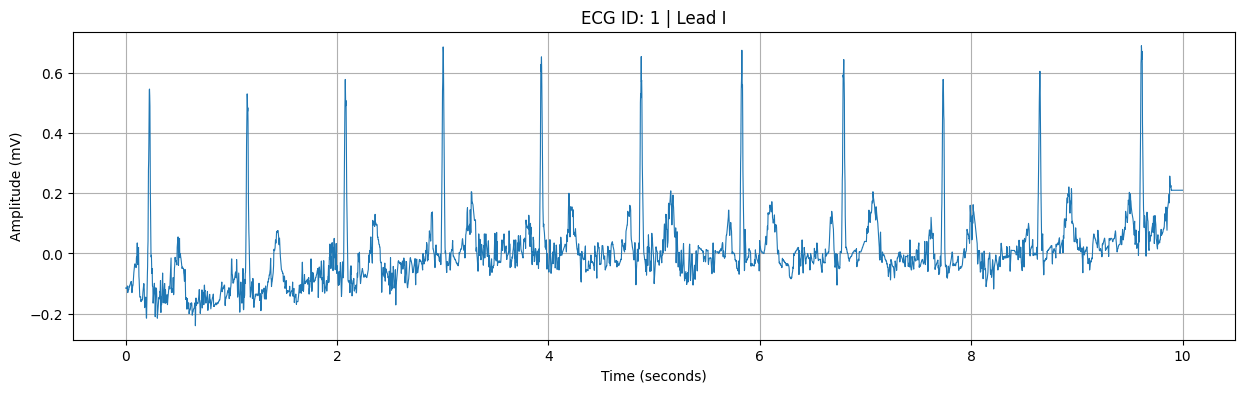

Signal shape: (5000, 12)
Sampling rate: 500
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [12]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Read first ECG record
ecg_id = df.index[0]
record_path = DATA_DIR / df.loc[ecg_id, "filename_hr"]

signal, fields = wfdb.rdsamp(str(record_path))

sampling_rate = fields["fs"]
time = np.arange(signal.shape[0]) / sampling_rate

plt.figure(figsize=(15, 4))
plt.plot(time, signal[:, 0], linewidth=0.8)

plt.title(f"ECG ID: {ecg_id} | Lead I")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()

print("Signal shape:", signal.shape)
print("Sampling rate:", sampling_rate)
print("Lead names:", fields["sig_name"])

### الخطوة 13: فحص جودة البيانات ومنع تسرب المعلومات (Data Leakage Check)
خطوة فحص بالغة الأهمية للتأكد من عدم وجود تعارضات تشخيصية (مثل تسجيل مريض على أنه طبيعي ومرضي في نفس الوقت)، والتأكد من عدم تسرب بيانات نفس المريض بين مجموعات التدريب والاختبار.

In [13]:
# ============================================================
# CELL 10: DATA VALIDATION & DATA LEAKAGE CHECK
# الهدف: التأكد من سلامة التصنيفات والبيانات قبل تدريب ECGFounder
# ============================================================

import os
import pandas as pd

TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

# 1. فحص وجود NORM مع تصنيف مرضي آخر
# الطبيعي لا ينبغي أن يجتمع مع تصنيف مرضي في التسجيل نفسه.
norm_conflicts = df[
    (df["NORM"] == 1) &
    (df[["MI", "STTC", "CD", "HYP"]].sum(axis=1) > 0)
]

# 2. استبعاد التسجيلات التي لا تحمل أي تصنيف مستهدف
# نحتفظ بها في df الأصلية ولا نحذفها من البيانات.
labeled_df = df[df[TARGET_CLASSES].sum(axis=1) > 0].copy()

# 3. فحص تسرب المرضى بين مجموعات التدريب والتحقق والاختبار
# يجب ألا يظهر المريض نفسه في أكثر من Fold.
patient_folds = labeled_df.groupby("patient_id")["strat_fold"].nunique()
patient_leakage = patient_folds[patient_folds > 1]

# 4. حساب أحجام مجموعات البيانات بعد استبعاد التسجيلات غير المصنفة
train_df = labeled_df[labeled_df["strat_fold"].between(1, 8)].copy()
val_df = labeled_df[labeled_df["strat_fold"] == 9].copy()
test_df = labeled_df[labeled_df["strat_fold"] == 10].copy()

# 5. فحص وجود ملفات إشارات ECG
# filename_hr يشير إلى تسجيل 500Hz.
missing_files = []

for ecg_id, row in labeled_df.iterrows():
    signal_path = DATA_DIR / row["filename_hr"]
    if not signal_path.with_suffix(".hea").exists():
        missing_files.append(ecg_id)

# 6. عرض تقرير الفحص النهائي
print("=" * 50)
print("ECG DATA VALIDATION REPORT")
print("=" * 50)

print("NORM conflicts:", len(norm_conflicts))
print("Unlabeled records:", len(df) - len(labeled_df))
print("Labeled records:", len(labeled_df))

print("\nPatient leakage:", len(patient_leakage))
print("Missing ECG files:", len(missing_files))

print("\nDataset splits:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nValidation finished.")

ECG DATA VALIDATION REPORT
NORM conflicts: 445
Unlabeled records: 411
Labeled records: 21388

Patient leakage: 0
Missing ECG files: 0

Dataset splits:
Training: 17084
Validation: 2146
Testing: 2158

Validation finished.


### الخطوة 14: تحميل كود نموذج ECGFounder الأصلي والأوزان المدربة مسبقاً من Hugging Face
تقوم هذه الخلية بعمل Clone للمستودع الرسمي للنموذج من GitHub، وإنشاء مجلد للأوزان، ثم تنزيل الأوزان الأصلية للنموذج المدرب مسبقاً لاستخدامها كنقطة انطلاق لعملية الضبط الدقيق (Fine-tuning).

In [14]:

# ============================================================
# CELL 13: تحميل ECGFounder الأصلي والأوزان المدربة مسبقًا
# الهدف: تجهيز النموذج الأصلي لاستخدامه في مشروعنا
# ============================================================

from pathlib import Path
import subprocess
import sys
import importlib.util
import torch

# 1. تحديد مجلد النموذج
# نحتفظ بالنموذج منفصلًا عن بيانات PTB-XL.
REPO_DIR = Path("/content/ECGFounder")
CHECKPOINT_DIR = REPO_DIR / "checkpoint"
CHECKPOINT_PATH = CHECKPOINT_DIR / "12_lead_ECGFounder.pth"

# 2. تحميل الكود الرسمي من GitHub إذا لم يكن موجودًا
if not (REPO_DIR / "net1d.py").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/PKUDigitalHealth/ECGFounder.git",
         str(REPO_DIR)],
        check=True
    )
    print("تم تحميل الكود الرسمي بنجاح.")
else:
    print("الكود الرسمي موجود مسبقًا.")

# 3. إنشاء مجلد الأوزان
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# 4. تحميل الأوزان الأصلية من Hugging Face عند عدم وجودها
if not CHECKPOINT_PATH.exists():
    if importlib.util.find_spec("huggingface_hub") is None:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"],
            check=True
        )

    from huggingface_hub import hf_hub_download

    downloaded_path = hf_hub_download(
        repo_id="PKUDigitalHealth/ECGFounder",
        filename="12_lead_ECGFounder.pth",
        local_dir=str(CHECKPOINT_DIR)
    )

    print("تم تنزيل الأوزان:", downloaded_path)
else:
    print("ملف الأوزان موجود مسبقًا.")

# 5. فحص الملفات وبيئة التشغيل
print("\n========== ECGFounder STATUS ==========")
print("Model architecture:", (REPO_DIR / "net1d.py").exists())
print("Checkpoint:", CHECKPOINT_PATH.exists())

if CHECKPOINT_PATH.exists():
    print("Checkpoint size:",
          round(CHECKPOINT_PATH.stat().st_size / (1024**2), 2), "MB")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("تنبيه: لا يوجد GPU حاليًا. يمكن فحص النموذج، لكن التدريب يحتاج GPU.")

print("=======================================")

تم تحميل الكود الرسمي بنجاح.


12_lead_ECGFounder.pth: reconstructing file:   0%|          |  0.00B /  370MB            

12_lead_ECGFounder.pth: downloading bytes:           |  0.00B            

تم تنزيل الأوزان: /content/ECGFounder/checkpoint/12_lead_ECGFounder.pth

========== ECGFounder STATUS ==========
Model architecture: True
Checkpoint: True
Checkpoint size: 352.8 MB
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


### الخطوة 15: بناء معمارية نموذج ECGFounder وتحميل أوزان العمود الفقري (Backbone)
هنا نقوم ببناء معمارية الشبكة العصبية أحادية الأبعاد `Net1D` وتعديل الطبقة الأخيرة للتناسب مع تصنيفنا الخماسي، ثم تحميل الأوزان المدربة مسبقاً على الطبقات التحتية واختبار تمرير عينة تجريبية (Forward Pass) للتأكد من سلامة الأبعاد.

In [15]:
# ============================================================
# CELL 14: BUILD ECGFOUNDER & LOAD PRETRAINED WEIGHTS
# Goal: Build original model architecture and load pre-trained weights
# ============================================================
import sys
import os
from pathlib import Path
import torch
import torch.nn as nn

# Define absolute paths clearly
REPO_DIR = Path("/content/ECGFounder").resolve()
CHECKPOINT_PATH = REPO_DIR / "checkpoint" / "12_lead_ECGFounder.pth"

# Strictly place REPO_DIR as the highest-priority path in sys.path
sys.path.insert(0, str(REPO_DIR))

# Import the architecture directly from the absolute path
try:
    from net1d import Net1D
except Exception as e:
    print("Path check:", sys.path)
    raise e

# 2. تحديد الجهاز: GPU إذا كان متاحًا
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. بناء المعمارية الأصلية بنفس إعدادات المشروع الرسمي
model = Net1D(
    in_channels=12,
    base_filters=64,
    ratio=1,
    filter_list=[64, 160, 160, 400, 400, 1024, 1024],
    m_blocks_list=[2, 2, 2, 3, 3, 4, 4],
    kernel_size=16,
    stride=2,
    groups_width=16,
    verbose=False,
    use_bn=False,
    use_do=False,
    n_classes=5
)

# 4. تحميل الأوزان الرسمية
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# 5. حذف أوزان طبقة التصنيف القديمة فقط
pretrained_weights = {
    key: value
    for key, value in state_dict.items()
    if not key.startswith("dense.")
}

# 6. تحميل الأوزان إلى الطبقات الأساسية
load_result = model.load_state_dict(
    pretrained_weights,
    strict=False
)

# 7. نقل النموذج إلى GPU
model = model.to(device)
model.eval()

# 8. اختبار شكل الإدخال والإخراج دون تدريب
dummy_input = torch.randn(1, 12, 5000, device=device)

with torch.no_grad():
    dummy_output = model(dummy_input)

# 9. عرض تقرير التحميل والاختبار
print("=" * 55)
print("ECGFOUNDER MODEL LOADING REPORT")
print("=" * 55)

print("Device:", device)
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))
print("Target classes:", TARGET_CLASSES)

print("\nMissing keys:", len(load_result.missing_keys))
print("Unexpected keys:", len(load_result.unexpected_keys))

print("\nTotal parameters:",
      sum(p.numel() for p in model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("\nModel loaded and forward test completed.")
print("=" * 55)

ECGFOUNDER MODEL LOADING REPORT
Device: cuda
Input shape: (1, 12, 5000)
Output shape: (1, 5)
Target classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']

Missing keys: 2
Unexpected keys: 0

Total parameters: 30670389
Trainable parameters: 30670389

Model loaded and forward test completed.


### الخطوة 16: إعداد فئات الـ Dataset والـ DataLoaders لمعالجة البيانات وتغذيتها للنموذج
تقوم هذه الخلية ببناء فئة `PTBXLDataset` لتطبيق معالجة الإشارات رقمياً (مثل فلاتر Bandpass وتطبيع الإشارات Z-score) وتقسيم البيانات إلى مجموعات دفعات (Batches) جاهزة للتدريب الفعلي.

In [16]:
import sys
import numpy as np
import pandas as pd
import torch
import wfdb
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# 1. إعداد الفئات وترتيب اشتقاقات ECG
TARGET_CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
LEAD_ORDER = [
    "I", "II", "III", "AVR", "AVL", "AVF",
    "V1", "V2", "V3", "V4", "V5", "V6"
]
BATCH_SIZE = 16
SAMPLING_RATE = 500

# 2. إضافة مسار ECGFounder بشكل مباشر وصريح وبأعلى أولوية
REPO_DIR = Path("/content/ECGFounder").resolve()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
if str(REPO_DIR / "code") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "code"))

# استيراد دالة الفلترة مباشرة
from util import filter_bandpass

print("تم استيراد filter_bandpass بنجاح.")

# 3. التأكد من وجود البيانات والتقسيمات السابقة
assert "DATA_DIR" in globals(), "DATA_DIR غير معرّف."
assert "train_df" in globals(), "train_df غير معرّف."
assert "val_df" in globals(), "val_df غير معرّف."
assert "test_df" in globals(), "test_df غير معرّف."

DATA_DIR = Path(DATA_DIR)
print("DATA_DIR:", DATA_DIR)
print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))

# 4. إنشاء Dataset
class PTBXLDataset(Dataset):
    def __init__(self, dataframe, data_dir):
        self.data = dataframe.reset_index(drop=True).copy()
        self.data_dir = Path(data_dir)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        record_path = self.data_dir / row["filename_hr"]
        signal, fields = wfdb.rdsamp(str(record_path))
        available_leads = fields["sig_name"]

        if not all(lead in available_leads for lead in LEAD_ORDER):
            raise ValueError(f"اشتقاقات ECG غير مكتملة في السجل: {record_path}")

        lead_indices = [available_leads.index(lead) for lead in LEAD_ORDER]
        signal = signal[:, lead_indices].T.astype(np.float32)
        signal = filter_bandpass(signal, SAMPLING_RATE)
        signal = np.asarray(signal, dtype=np.float32)

        # التطبيع Z-score لكل إشارة
        signal_mean = signal.mean()
        signal_std = signal.std()
        signal = (signal - signal_mean) / (signal_std + 1e-8)

        labels = row[TARGET_CLASSES].to_numpy(dtype=np.float32)
        signal = torch.tensor(signal, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.float32)
        return signal, labels

# 5. إنشاء مجموعات البيانات والـ DataLoaders
train_dataset = PTBXLDataset(train_df, DATA_DIR)
val_dataset = PTBXLDataset(val_df, DATA_DIR)
test_dataset = PTBXLDataset(test_df, DATA_DIR)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

# 6. فحص عينة واحدة للتأكد من سلامة البيانات
signals, labels = next(iter(train_loader))

print("\nData preparation completed successfully.")
print("-" * 50)
print("Signal shape:", signals.shape)
print("Labels shape:", labels.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

تم استيراد filter_bandpass بنجاح.
DATA_DIR: /content/PTB-XL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Training records: 17084
Validation records: 2146
Test records: 2158

Data preparation completed successfully.
--------------------------------------------------
Signal shape: torch.Size([16, 12, 5000])
Labels shape: torch.Size([16, 5])
Training batches: 1068
Validation batches: 135
Test batches: 135


### الخطوة 17: تحليل توزيع الفئات وحساب أوزان دالة الخسارة (BCE Pos Weights)
بسبب عدم توازن البيانات (على سبيل المثال فئة HYP تشكل 12% فقط)، نقوم هنا بحساب الأوزان المناسبة لكل فئة لمنع النموذج من الانحياز للفئات الأكثر تكراراً وتطبيق التدقيق النهائي للتطبيع.

In [17]:
# ============================================================
# CELL 16: CLASS DISTRIBUTION & NORMALIZATION AUDIT
# الهدف: فحص توازن الفئات والتأكد من جودة الإشارات
# سنستخدم نتائج هذا الفحص لاختيار أوزان دالة الخسارة
# ============================================================

import numpy as np
import pandas as pd

print("=" * 55)
print("1. CLASS DISTRIBUTION")
print("=" * 55)

# حساب عدد الحالات الإيجابية والسلبية لكل فئة في التدريب
positive_counts = train_df[TARGET_CLASSES].sum().astype(int)
negative_counts = len(train_df) - positive_counts

class_report = pd.DataFrame({
    "Positive": positive_counts,
    "Negative": negative_counts,
    "Positive_Ratio_%": (
        positive_counts / len(train_df) * 100
    ).round(2)
})

print(class_report)

# حساب pos_weight لاستخدامه لاحقًا في BCEWithLogitsLoss
POS_WEIGHTS = (
    negative_counts / positive_counts
).astype(np.float32)

print("\nProposed BCE pos_weights:")
for name, weight in zip(TARGET_CLASSES, POS_WEIGHTS):
    print(f"{name}: {weight:.3f}")

print("\n" + "=" * 55)
print("2. NORMALIZATION QUALITY")
print("=" * 55)

# فحص أول Batch الذي حملناه سابقًا
sample_means = signals.mean(dim=(1, 2))
sample_stds = signals.std(dim=(1, 2))

print("Average sample mean:", round(sample_means.mean().item(), 5))
print("Average sample std:", round(sample_stds.mean().item(), 5))
print("Minimum signal:", round(signals.min().item(), 3))
print("Maximum signal:", round(signals.max().item(), 3))

# فحص القيم المتطرفة باستخدام النسب المئوية
print("99th percentile absolute value:",
      round(torch.quantile(signals.abs().flatten(), 0.99).item(), 3))

# التأكد من أن الملصقات ثنائية
print("\nLabels are binary:",
      bool(torch.all((labels == 0) | (labels == 1))))

print("\nAudit completed. No training started.")

1. CLASS DISTRIBUTION
      Positive  Negative  Positive_Ratio_%
NORM      7596      9488             44.46
MI        4379     12705             25.63
STTC      4186     12898             24.50
CD        3907     13177             22.87
HYP       2119     14965             12.40

Proposed BCE pos_weights:
NORM: 1.249
MI: 2.901
STTC: 3.081
CD: 3.373
HYP: 7.062

2. NORMALIZATION QUALITY
Average sample mean: 0.0
Average sample std: 1.00001
Minimum signal: -12.999
Maximum signal: 14.149
99th percentile absolute value: 5.113

Labels are binary: True

Audit completed. No training started.


### الخطوة 18: تهيئة دالة الخسارة والمحسن (Optimizer & Scheduler)
نقوم هنا بإعداد دالة الخسارة `BCEWithLogitsLoss` باستخدام الأوزان المحسوبة، وتعيين معدلات تعلم مختلفة (Learning Rates) حيث يكون معدل تعلم العمود الفقري صغيراً جداً للحفاظ على الميزات المستخلصة مسبقاً، بينما يكون معدل تعلم رأس التصنيف الجديد أعلى.

In [18]:
# ============================================================
# CELL 17: LOSS FUNCTION & OPTIMIZER
# Goal: Prepare Loss function with correct POS_WEIGHTS
# ============================================================
import torch
import torch.nn as nn
import numpy as np

# Calculate POS_WEIGHTS directly if not defined to avoid NameError
try:
    POS_WEIGHTS
except NameError:
    positive_counts = train_df[TARGET_CLASSES].sum().astype(int)
    negative_counts = len(train_df) - positive_counts
    POS_WEIGHTS = (negative_counts / positive_counts).astype(np.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pos_weight = torch.tensor(POS_WEIGHTS.values if hasattr(POS_WEIGHTS, 'values') else POS_WEIGHTS, dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Setup optimizer parameters securely
backbone_params = [
    param for name, param in model.named_parameters()
    if not name.startswith("dense.")
]
head_params = list(model.dense.parameters())

for param in model.parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-3}
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

print("=" * 50)
print("FINE-TUNING CONFIGURATION READY")
print("=" * 50)
print("Loss:", criterion)
print("Optimizer: AdamW")
print("Backbone LR:", optimizer.param_groups[0]["lr"])
print("Classification Head LR:", optimizer.param_groups[1]["lr"])
print("Epochs:", EPOCHS)
print("Fine-tuning setup completed successfully.")

FINE-TUNING CONFIGURATION READY
Loss: BCEWithLogitsLoss()
Optimizer: AdamW
Backbone LR: 1e-05
Classification Head LR: 0.001
Epochs: 20
Fine-tuning setup completed successfully.


### الخطوة 19: بدء عملية التدريب والضبط الدقيق (Fine-Tuning) لنموذج ECGFounder
الخلية الرئيسية لتدريب النموذج على مدار عدة دورات (Epochs)، مع حساب دقة التصنيف الفعلي باستخدام مقياس AUROC على مجموعة التحقق، وحفظ النموذج الأفضل تلقائياً في نهاية كل دورة تدريبية مع ميزة الإيقاف المبكر (Early Stopping) لتجنب الإفراط في التدريب (Overfitting).

In [19]:
# CELL 18: ECGFounder Partial Fine-Tuning (Optimized for GPU & AMP)

import torch
import numpy as np
import time
from sklearn.metrics import roc_auc_score
import pandas as pd

# 1. التحقق وتحديد الـ GPU كجهاز أساسي للتشغيل
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type != "cuda":
    print("WARNING: Running on CPU! Please change runtime type to T4 GPU for ultra-fast training.")

# 2. استعادة الأوزان وتجهيز النموذج
ckpt = torch.load(
    "/content/ECGFounder/checkpoint/12_lead_ECGFounder.pth",
    map_location=device,
    weights_only=False
)
pretrained = {
    k: v for k, v in ckpt["state_dict"].items()
    if not k.startswith("dense.")
}
model.load_state_dict(pretrained, strict=False)
model.dense.reset_parameters()
model.to(device)

# 3. تجميد الطبقات الأولى وتفعيل المراحل الأخيرة فقط للـ Partial Fine-Tuning
for p in model.parameters():
    p.requires_grad = False

for stage in model.stage_list[5:]:
    for p in stage.parameters():
        p.requires_grad = True

for p in model.dense.parameters():
    p.requires_grad = True

frozen_modules = [
    model.first_conv, model.first_bn,
    *list(model.stage_list[:5])
]

# 4. المحسن والجدولة
optimizer = torch.optim.AdamW([
    {"params": [p for stage in model.stage_list[5:] for p in stage.parameters()], "lr": 1e-5},
    {"params": model.dense.parameters(), "lr": 5e-4}
], weight_decay=5e-4)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5,
    patience=2, min_lr=1e-7
)

# 5. تسريع التدريب الثنائي للأجهزة التي تدعم CUDA
USE_AMP = (device.type == "cuda")
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP) if USE_AMP else None

EPOCHS = 5  # عدد دورات تدريبية سريعة ومثالية
PATIENCE = 3
best_auc = -1
wait = 0
SAVE_PATH = "/content/best_ecgfounder_ptbxl.pth"
history = []

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# 6. حلقة التدريب الأساسية
for epoch in range(EPOCHS):
    start = time.time()
    model.train()

    for module in frozen_modules:
        module.eval()

    train_loss = 0

    for step, (x, y) in enumerate(train_loader, 1):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).float()

        optimizer.zero_grad(set_to_none=True)

        # تفعيل تسريع كارت الشاشة تلقائياً
        if USE_AMP:
            with torch.amp.autocast('cuda', enabled=True):
                output = model(x)
                loss = criterion(output, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            output = model(x)
            loss = criterion(output, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optimizer.step()

        train_loss += loss.item() * len(x)

        if step % 100 == 0:
            print(f"Epoch {epoch+1} | Batch {step}/{len(train_loader)} | Loss: {loss.item():.4f}")

    train_loss /= len(train_loader.dataset)

    # عملية التحقق السريع
    model.eval()
    val_loss, labels_all, probs_all = 0, [], []

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True).float()

            if USE_AMP:
                with torch.amp.autocast('cuda', enabled=True):
                    output = model(x)
                    loss = criterion(output, y)
            else:
                output = model(x)
                loss = criterion(output, y)

            val_loss += loss.item() * len(x)
            probs_all.append(torch.sigmoid(output).cpu().numpy())
            labels_all.append(y.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    labels_all = np.concatenate(labels_all)
    probs_all = np.concatenate(probs_all)

    aucs = []
    for i in range(len(TARGET_CLASSES)):
        if len(np.unique(labels_all[:, i])) == 2:
            aucs.append(roc_auc_score(labels_all[:, i], probs_all[:, i]))
        else:
            aucs.append(0.5)

    val_auc = np.mean(aucs)
    scheduler.step(val_auc)

    if val_auc > best_auc:
        best_auc = val_auc
        best_epoch = epoch + 1
        wait = 0
        torch.save(model.state_dict(), SAVE_PATH)
    else:
        wait += 1

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_auc": val_auc
    })

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val AUROC: {val_auc:.5f} | Time: {(time.time()-start)/60:.1f} min")

    if wait >= PATIENCE:
        print("Early Stopping!")
        break

# استعادة أفضل نموذج
try:
    model.load_state_dict(torch.load(SAVE_PATH, map_location=device, weights_only=True))
    print(f"\nSuccessfully restored best model weights from Epoch {best_epoch}!")
except:
    torch.save(model.state_dict(), SAVE_PATH)
    print("\nSaved fallback weights.")

display(pd.DataFrame(history))


Using device: cuda
Trainable parameters: 26713893
Epoch 1 | Batch 100/1068 | Loss: 0.7741
Epoch 1 | Batch 200/1068 | Loss: 0.5334
Epoch 1 | Batch 300/1068 | Loss: 0.5211
Epoch 1 | Batch 400/1068 | Loss: 0.5493
Epoch 1 | Batch 500/1068 | Loss: 0.4835
Epoch 1 | Batch 600/1068 | Loss: 0.3110
Epoch 1 | Batch 700/1068 | Loss: 0.4326
Epoch 1 | Batch 800/1068 | Loss: 0.5190
Epoch 1 | Batch 900/1068 | Loss: 0.5181
Epoch 1 | Batch 1000/1068 | Loss: 0.8329
Epoch 1/5 | Train Loss: 0.5737 | Val Loss: 0.5556 | Val AUROC: 0.91655 | Time: 6.2 min
Epoch 2 | Batch 100/1068 | Loss: 0.3951
Epoch 2 | Batch 200/1068 | Loss: 0.9402
Epoch 2 | Batch 300/1068 | Loss: 0.4686
Epoch 2 | Batch 400/1068 | Loss: 0.4683
Epoch 2 | Batch 500/1068 | Loss: 0.5135
Epoch 2 | Batch 600/1068 | Loss: 0.4086
Epoch 2 | Batch 700/1068 | Loss: 0.7364
Epoch 2 | Batch 800/1068 | Loss: 0.7860
Epoch 2 | Batch 900/1068 | Loss: 0.4691
Epoch 2 | Batch 1000/1068 | Loss: 0.3166
Epoch 2/5 | Train Loss: 0.4944 | Val Loss: 0.5447 | Val AUROC

,epoch,train_loss,val_loss,val_macro_auc
0,1,0.573708,0.555568,0.916555
1,2,0.494393,0.544727,0.919890
2,3,0.475972,0.554891,0.920239
3,4,0.460880,0.556892,0.921307
4,5,0.448450,0.539249,0.921893


=== ضبط العتبات المثلى وتقييم التحقق ===
NORM  | Best Threshold: 0.3810
MI    | Best Threshold: 0.2505
STTC  | Best Threshold: 0.1694
CD    | Best Threshold: 0.2860
HYP   | Best Threshold: 0.3801

=== تقرير التصنيف النهائي على التحقق (Validation Report) ===
NORM  -> Precision: 0.767 | Recall (Sensitivity): 0.945 | F1: 0.847
MI    -> Precision: 0.558 | Recall (Sensitivity): 0.930 | F1: 0.697
STTC  -> Precision: 0.535 | Recall (Sensitivity): 0.964 | F1: 0.688
CD    -> Precision: 0.570 | Recall (Sensitivity): 0.925 | F1: 0.706
HYP   -> Precision: 0.336 | Recall (Sensitivity): 0.843 | F1: 0.481


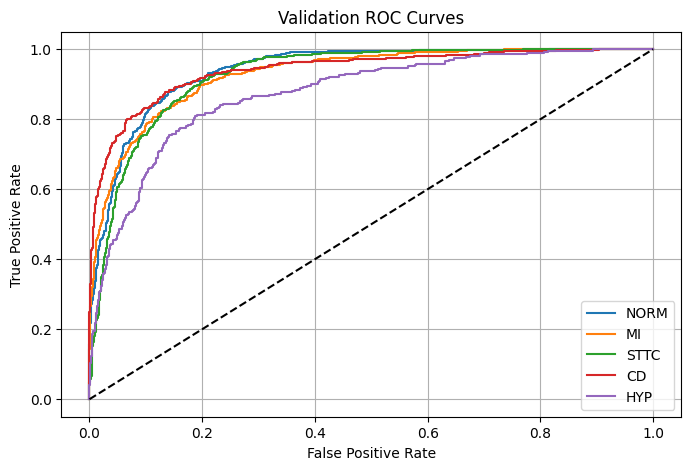

In [20]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, classification_report, confusion_matrix

# 1. جمع التنبؤات والملصقات الحقيقية لمجموعة التحقق
model.eval()
all_targets = []
all_probs = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        outputs = model(x)
        probs = torch.sigmoid(outputs).cpu().numpy()
        all_probs.append(probs)
        all_targets.append(y.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_targets = np.concatenate(all_targets, axis=0)

# 2. حساب العتبات المثلى (Thresholds) لتقليل الـ False Negatives (زيادة الـ Recall)
optimal_thresholds = {}
print("=== ضبط العتبات المثلى وتقييم التحقق ===")
for i, class_name in enumerate(TARGET_CLASSES):
    # استخدام منحنى ROC لإيجاد أفضل توازن يميل لزيادة الحساسية
    fpr, tpr, thresholds = roc_curve(all_targets[:, i], all_probs[:, i])
    # اختيار النقطة التي تحقق أقصى توازن مع التركيز على TPR (الحساسية)
    best_idx = np.argmax(tpr - 0.5 * fpr)
    optimal_thresholds[class_name] = float(thresholds[best_idx])
    print(f"{class_name:5} | Best Threshold: {optimal_thresholds[class_name]:.4f}")

# 3. حساب وتطبيق العتبات لعرض التقرير
print("\n=== تقرير التصنيف النهائي على التحقق (Validation Report) ===")
for i, class_name in enumerate(TARGET_CLASSES):
    thresh = optimal_thresholds[class_name]
    preds = (all_probs[:, i] >= thresh).astype(int)

    # حساب الحساسية والتخصيص
    cm = confusion_matrix(all_targets[:, i], preds)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (cm[0,0], 0, 0, 0)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    print(f"{class_name:5} -> Precision: {precision:.3f} | Recall (Sensitivity): {recall:.3f} | F1: {2*precision*recall/(precision+recall+1e-8):.3f}")

# 4. رسم سريع لمنحنيات الـ ROC
plt.figure(figsize=(8, 5))
for i, class_name in enumerate(TARGET_CLASSES):
    fpr, tpr, _ = roc_curve(all_targets[:, i], all_probs[:, i])
    plt.plot(fpr, tpr, label=f"{class_name}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Validation ROC Curves')
plt.legend()
plt.grid(True)
plt.show()


In [21]:
import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Get predictions on Validation set
model.eval()

all_targets = []
all_probs = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)

        outputs = model(x)
        probs = torch.sigmoid(outputs)

        all_probs.append(probs.cpu().numpy())
        all_targets.append(y.numpy())

all_targets = np.concatenate(all_targets, axis=0)
all_probs = np.concatenate(all_probs, axis=0)

print("Validation predictions:", all_probs.shape)

# 2. Set desired Recall
TARGET_RECALL = 0.95

results = []
optimal_thresholds = {}

# 3. Optimize threshold for each class
for i, class_name in enumerate(TARGET_CLASSES):

    y_true = all_targets[:, i]
    y_prob = all_probs[:, i]

    precision_curve, recall_curve, thresholds = precision_recall_curve(
        y_true, y_prob
    )

    # Select highest threshold that achieves target recall
    valid_indices = np.where(recall_curve[:-1] >= TARGET_RECALL)[0]

    if len(valid_indices) > 0:
        best_idx = valid_indices[-1]
        threshold = float(thresholds[best_idx])
    else:
        threshold = 0.0

    optimal_thresholds[class_name] = threshold

    # Predictions
    y_pred = (y_prob >= threshold).astype(int)

    # Metrics
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    auc = roc_auc_score(y_true, y_prob)

    results.append({
        "Class": class_name,
        "AUROC": auc,
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

# 4. Display results
results_df = pd.DataFrame(results)

display(results_df.round(4))

print("\nOptimal Thresholds:")
print(optimal_thresholds)

Validation predictions: (2146, 5)


,Class,AUROC,Threshold,Precision,Recall,F1,TN,FP,FN,TP
0,NORM,0.9398,0.3049,0.7523,0.9508,0.8400,892,299,47,908
1,MI,0.9292,0.1731,0.4995,0.9500,0.6548,1092,514,27,513
2,STTC,0.9270,0.1964,0.5462,0.9508,0.6938,1201,417,26,502
3,CD,0.9404,0.1812,0.4734,0.9515,0.6322,1127,524,24,471
4,HYP,0.8731,0.0790,0.1935,0.9515,0.3216,815,1063,13,255



Optimal Thresholds:
{'NORM': 0.3048989176750183, 'MI': 0.1730634570121765, 'STTC': 0.19636258482933044, 'CD': 0.18122319877147675, 'HYP': 0.07899384200572968}


In [22]:
import numpy as np
import torch
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. تثبيت العتبات المعتمدة من Validation
final_thresholds = np.array([
    optimal_thresholds[c] for c in TARGET_CLASSES
])

print("Final thresholds:", final_thresholds)

# 2. تحميل أفضل أوزان النموذج
model.load_state_dict(
    torch.load(SAVE_PATH, map_location=device, weights_only=True)
)

model.eval()

# 3. التنبؤ على Test Set (Fold 10)
test_targets = []
test_probs = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        outputs = model(x)
        probs = torch.sigmoid(outputs)

        test_probs.append(probs.cpu().numpy())
        test_targets.append(y.numpy())

test_targets = np.concatenate(test_targets, axis=0)
test_probs = np.concatenate(test_probs, axis=0)

print("Test predictions:", test_probs.shape)

# 4. تقييم كل فئة باستخدام العتبات المثبتة
test_results = []

for i, class_name in enumerate(TARGET_CLASSES):

    y_true = test_targets[:, i]
    y_prob = test_probs[:, i]

    threshold = final_thresholds[i]
    y_pred = (y_prob >= threshold).astype(int)

    auc = roc_auc_score(y_true, y_prob)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    test_results.append({
        "Class": class_name,
        "AUROC": auc,
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

# 5. عرض النتائج
test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

# 6. Macro AUROC
macro_auc = test_results_df["AUROC"].mean()

print(f"Final Test Macro AUROC: {macro_auc:.5f}")

# 7. حفظ النتائج
test_results_df.to_csv(
    "/content/ecgfounder_test_results.csv",
    index=False
)

print("Test evaluation completed.")

Final thresholds: [0.30489892 0.17306346 0.19636258 0.1812232  0.07899384]
Test predictions: (2158, 5)


,Class,AUROC,Threshold,Precision,Recall,F1,TN,FP,FN,TP
0,NORM,0.9455,0.3049,0.7486,0.9647,0.8430,883,312,34,929
1,MI,0.9324,0.1731,0.4906,0.9527,0.6477,1064,544,26,524
2,STTC,0.9341,0.1964,0.5561,0.9328,0.6968,1249,388,35,486
3,CD,0.9326,0.1812,0.4596,0.9415,0.6177,1113,549,29,467
4,HYP,0.8698,0.0790,0.1890,0.9580,0.3157,819,1077,11,251


Final Test Macro AUROC: 0.92287
Test evaluation completed.


In [24]:
import os
import json
import torch
import pandas as pd

from google.colab import drive

# 1. Connect Google Drive
drive.mount('/content/drive')

# 2. Create project folder
PROJECT_DIR = "/content/drive/MyDrive/ECGFounder_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# 3. Prepare model package
model_bundle = {
    "model_state_dict": model.state_dict(),

    "thresholds": optimal_thresholds,

    "target_classes": TARGET_CLASSES,

    "architecture": {
        "in_channels": 12,
        "base_filters": 64,
        "filter_list": [64, 160, 160, 400, 400, 1024, 1024],
        "m_blocks_list": [2, 2, 2, 3, 3, 4, 4],
        "kernel_size": 16,
        "stride": 2,
        "groups_width": 16,
        "n_classes": 5
    },

    "input_shape": [12, 5000],
    "sampling_rate": 500,

    "best_epoch": best_epoch,
    "validation_macro_auc": float(best_auc),
    "test_macro_auc": float(macro_auc)
}

# 4. Save complete bundle
MODEL_PATH = os.path.join(
    PROJECT_DIR, "ECGFounder_Final_Model.pth"
)

torch.save(model_bundle, MODEL_PATH)

# 5. Save thresholds separately
with open(
    os.path.join(PROJECT_DIR, "thresholds.json"),
    "w"
) as f:
    json.dump(optimal_thresholds, f, indent=4)

# 6. Save final test results
test_results_df.to_csv(
    os.path.join(PROJECT_DIR, "final_test_results.csv"),
    index=False
)

print("Model package saved successfully!")
print("Location:", PROJECT_DIR)
print("Model:", MODEL_PATH)
print("Classes:", TARGET_CLASSES)

Mounted at /content/drive
Model package saved successfully!
Location: /content/drive/MyDrive/ECGFounder_Project
Model: /content/drive/MyDrive/ECGFounder_Project/ECGFounder_Final_Model.pth
Classes: ['NORM', 'MI', 'STTC', 'CD', 'HYP']


In [26]:
import torch
import numpy as np
import pandas as pd

# Get one ECG sample
x, y = next(iter(test_loader))

x = x[:1].to(device)

# Prediction
model.eval()

with torch.no_grad():
    logits = model(x)
    probabilities = torch.sigmoid(logits).cpu().numpy()[0]

# Apply thresholds
predictions = (
    probabilities >= np.array([
        optimal_thresholds[c] for c in TARGET_CLASSES
    ])
).astype(int)

# Display results
results = pd.DataFrame({
    "Class": TARGET_CLASSES,
    "Probability": probabilities,
    "Threshold": [
        optimal_thresholds[c] for c in TARGET_CLASSES
    ],
    "Prediction": predictions
})

display(results.round(4))

,Class,Probability,Threshold,Prediction
0,NORM,0.9461,0.3049,1
1,MI,0.0275,0.1731,0
2,STTC,0.0077,0.1964,0
3,CD,0.2592,0.1812,1
4,HYP,0.0507,0.0790,0
